# Assignment 4: DEM, Silo Discharge and the Beverloo Law

**6EMA02 Particle-based Simulations, 2026-2027 edition**
Discrete element method · contacts and friction · granular flow

## How this assignment is assessed: read this first

This notebook is both the assignment text and your report. Task cells
(like this one) are the assignment text and are marked read-only. Jupyter
enforces that; some editors (VS Code among them) do not, so simply leave
them untouched either way: hand-ins are checked against the released
notebook, and modified task cells are flagged. You write your answers in
the cells below each task and hand in this same notebook, **executed**,
together with an HTML export, your code, and the data files the notebook
loads (layout at the end of this notebook).

Your report is **not graded on its content**. Its result is determined in
the individual oral examination at the end of the quartile: the exam is a
conversation about *your* code and *your* results, with this notebook on
screen. Write it as your defence dossier: concise, bullet answers are
fine, every claim something you can stand behind. A report you never hand
in scores 0 for its weight in the final grade; a handed-in report's
result *is* your oral grade.

**AI and sources.** You may use AI assistants (ChatGPT, Claude, Copilot,
…) freely in this course, for code, analysis, and text. Declare the use
briefly in the *Sources* section below, along with any other external
sources: anything in your submission (code, text, data, results) that
your group did not produce itself. Declared sources are never penalised:
nobody grades the text of your report or the style of your code. The oral
examination assesses what *you* understand about the simulation you hand
in. Anything in your submission is fair game, and "we didn't write that
part" is not an available answer. Presenting undeclared external work as
your own is academic misconduct and is treated as such.

## Group

- **Group ID:** …
- **Members:** Tomas Dadikozyan (1959123), Shree Patil (1966723)

## The physics: granular matter is its own state

Sand pours like a liquid, holds a slope like a solid, and sprays like a
gas, sometimes within one second and one apparatus. Two features of the
grains explain almost all of it, and both are absent from A2 and A3.

**Contacts are dissipative.** Two grains that collide do not bounce back
with the same speed: energy goes into deformation, sound and heat. The
loss is quantified by the **coefficient of restitution**
$e = v_\mathrm{after}/v_\mathrm{before}$, which is 0.92 for our
particles: nearly elastic, and still enough that an unstirred granular
system comes to rest. There is no temperature worth speaking of, because
thermal energy is utterly negligible against $m g d_p$ for a millimetre
grain. Without external driving, granular matter simply stops.

**Contacts are frictional, and they remember.** A grain resting on a
slope is held by static friction. Friction is not a function of the
current positions alone: it depends on how much the contact has been
loaded *since it formed*. That is why the code carries a **tangential
displacement per contact** and why contact history has to survive from
step to step. It is the deepest structural difference from your MD code,
where a pair interaction depends only on the current separation.

**How the forces are modelled.** There is no interaction potential here.
Two particles interact only when they geometrically overlap, and the
model is a **spring and dashpot** in the normal direction, plus a
tangential spring limited by the Coulomb condition
$|\mathbf{F}_t| \le \mu |\mathbf{F}_n|$ (the Cundall-Strack model). The
spring gives the elastic rebound, the dashpot the dissipation, and the
Coulomb limit turns sticking into sliding. Two consequences you will meet
directly:

- The spring and dashpot constants are not free parameters you set. They
  are **derived** from a restitution coefficient and a contact time, and
  Part A verifies that the model gives back the restitution it was built
  from.
- The contact time sets the time step: you need many steps per collision
  to resolve it, so $\Delta t$ is tied to the contact duration and not to
  anything about the flow.

**The physics you will actually test.** A silo is a beautiful case
because it violates the intuition trained on liquids. A draining water
tank slows down as it empties, since the pressure at the outlet falls
with the head of liquid. A silo does not: its discharge rate is
**independent of the fill height**. The reason is that grains transmit
stress through force chains that push outward on the walls, so wall
friction carries most of the weight and the pressure near the bottom
saturates once the filling is more than about a diameter deep. This is
Janssen's classic result, and it is why the outflow depends on the
orifice and not on how much is above it.

What is left is a dimensional argument. If the flow is set by grains
falling freely from an arch of the order of the orifice size, the
velocity scales as $\sqrt{gD}$ and the area as $D^2$, so the mass flow
goes as $\rho_b \sqrt{g} D^{5/2}$. Grains cannot pass within one radius
of the rim, which turns $D$ into an effective $D - k d_p$. That is the
**Beverloo correlation**

$$Q = C\,\rho_b\,\sqrt{g}\,(D - k\,d_p)^{5/2},$$

with $Q$ the mass discharge rate, $\rho_b$ the bulk density of the
packed bed, $d_p$ the particle diameter, and $C$ and $k$ empirical
constants: typically $C \approx 0.58$ (reported values 0.55 to 0.65)
and $k \approx 1.5$. Your job in Part D is to test it quantitatively on
your own simulated silo. At small orifices the same physics turns
against the flow: an arch that forms across the opening can be strong
enough to hold, and the silo clogs. That is task D4.

## The model: particles, walls and parameters

| | Normal restitution | Tangential restitution | Friction |
|---|---|---|---|
| Particle-particle | 0.92 | 0.33 | 0.50 |
| Particle-wall (all walls) | 0.85 | 0.33 | 0.45 |

- Particle diameter $d_p = 2.0$ mm (radii uniform between 0.975 and
  1.024 mm), material density $\rho_p = 2500\ \mathrm{kg/m^3}$,
  mean particle mass $1.046 \times 10^{-5}$ kg.
- Contact time $t_c = 0.219$ ms, the same for a particle-particle and a
  particle-wall contact; time step $\Delta t = t_c/20 = 1.095 \times
  10^{-5}$ s.
- The silo, for Parts C and D: 7500 particles in a cylinder of radius
  $R_\mathrm{cyl} = 17.7$ mm (a diameter of 17.7 $d_p$), bottom plate at
  $z_\mathrm{silo} = 53.1$ mm above the floor of the box, settled fill
  about 58 mm high. All of this is already set in
  `set_silo_geometry`: you do not size anything yourself.

## The code, and how to work with it

The starting code is `DEM_student_v7.1.0.zip` under Files ▸ Code. It has
the same structure as your MD code, so most of it will be familiar.
Unpack it into `code/` in your working directory.

**Every piece of code you write already exists** as a function that
compiles, runs, and is called from the right place; the `\todo` inside
it says exactly what to fill in. Open `html/index.html` from the zip: its
*todo list* has them all. In short:

| Part | function, file | what you write |
|---|---|---|
| A | `initialise_collision`, initialise.c | one particle at the wall, or two head-on |
| B | `update_parameters`, setparameters.c | rotate gravity from $t_\mathrm{tilt}$ on |
| C1 | `cylinder_wall`, walls.c | the silo wall |
| C2 | `silo_bottom_wall`, walls.c; `update_parameters` | the edge of the hole in the plate (the flat plate is given), and opening the orifice at $t_\mathrm{open}$ |
| C3 | `initialise_positions_silo`, initialise.c | the fill: a loose lattice inside the cylinder |
| D2 | `count_in_silo`, walls.c | the number of particles above the plate |

That is all the C you write. **All analysis is done in Python**, from the
table the program prints and from the trajectory file.

**Choosing a run.** The macro `RUN` at the top of `setparameters.c`
selects the set-up: 1 is the test collision of Part A, 2 the tilted bed
of Part B, 3 the silo of Parts C and D. It and the other settings you
vary (`NUM_TEST`, `V_IMPACT`, `DT_FRACTION`, `TILT_RATE`, `D_ORIFICE`,
`T_DISCHARGE`) have defaults there and can be given on the command line,
so every run is one command you can copy into your build log:

```
gcc -O3 -DRUN=1 -DNUM_TEST=2 -DV_IMPACT=1.0 *.c -o dem -lm    # Part A, two particles head-on
gcc -O3 -DRUN=2 *.c -o dem -lm                                # Part B
gcc -O3 -DRUN=3 -DD_ORIFICE=8 -DT_DISCHARGE=1.0 *.c -o dem -lm  # Part D, orifice of 8 d_p
./dem > run.dat
```

(Linux and macOS; on Windows use MSYS2. For debugging:
`gcc -g -Wall -Wextra *.c -o dem_debug -lm`.)

**Output.** Every run prints a table: step, time, coordination number
$Z$ (contacts per particle), potential, kinetic and total energy, and
`N_silo`, the number of particles in the silo. The first line, starting
with `# run`, records the geometry and the time step. Redirect the table
to a file and load it with `numpy.loadtxt`, which skips the `#` lines.
Every run also writes `trajectories.xyz`, a frame every 0.022 s.

**Each run in its own directory.** Every run writes `trajectories.xyz`
and `restart.dat` into the directory it runs in, so two runs in one
directory overwrite each other. Make a directory per run, e.g.
`mkdir -p runs/D8 && cd runs/D8 && ../../code/dem > run.dat`. Runs in
different directories can go in parallel on different cores.

**Visualisation.** Open `trajectories.xyz` in OVITO: the file states the
box, the radii and the speed itself, so no column mapping is needed.
Colour by speed (*Add modification ▸ Color coding ▸* `speed`), and to see
inside the silo add *Slice* (normal (0, 1, 0), slab width 4 mm, through
the centre of the box). Without the slice you only see the particles
against the wall.

**Reading a trajectory in Python.** A frame is a line with the number of
particles, a line with the box and the time, then one line per particle:
`C x y z radius speed`, in SI units. This reads all frames:

```python
import numpy as np, re
def read_xyz(path):
    frames, times = [], []
    with open(path) as f:
        while (line := f.readline()):
            n = int(line)
            times.append(float(re.search(r"Time=(\S+)", f.readline()).group(1)))
            rows = [f.readline() for _ in range(n)]
            frames.append(np.loadtxt(rows, usecols=(1, 2, 3, 4, 5)))
    return np.array(times), frames      # each frame: columns x, y, z, radius, speed
```

Do not hand in trajectories (a silo run writes 20 to 60 MB). Save the one
frame you analyse, e.g. with `np.savetxt`, and the images you make.

**What you do not need to do.** No restart files: every run settles from
the same random seed, so the bed at $t_\mathrm{tilt}$ or
$t_\mathrm{open}$ is identical in every run of a kind. No analysis code
in C. No sizing of the silo. No hunting for the right run length: the
table below gives it.

**Python environment:** the same `pbs-env` as in the earlier
assignments, from `requirements.txt`; `nb2html.py` for the HTML you hand
in and `check_my_submission.py` before you submit. See the Canvas page
*Working on the assignments*.

## The runs, at a glance

Times are for one core of a reference workstation; a laptop may take two
or three times longer. Apart from the 24 tiny runs of Part A, seven runs in
all, about 15 minutes of computing on the reference machine.

| task | command (`gcc -O3 … *.c -o dem -lm`) | simulated | CPU |
|---|---|---|---|
| A | `-DRUN=1 -DNUM_TEST=1` or `2`, `-DV_IMPACT=0.1`, `0.3`, `1.0`, `-DDT_FRACTION=0.2`, `0.1`, `0.05`, `0.025`: 24 runs, a shell loop | 2 ms | < 1 s each |
| B | `-DRUN=2` (20 °/s) and `-DRUN=2 -DTILT_RATE=10` | 1.5 s, 2.7 s | 25 s, 45 s |
| C, D1, D2, D3 | `-DRUN=3` ($D = 7 d_p$, the default) | 2.3 s | 4 min |
| D3 | `-DRUN=3 -DD_ORIFICE=6 -DT_DISCHARGE=1.5`, `=8 … =1.0`, `=9 … =0.8` | 1.1 to 1.8 s | 2 to 3 min each |
| D4 | `-DRUN=3 -DD_ORIFICE=3 -DT_DISCHARGE=0.8` | 1.1 s | 2 min |

Long runs are done in the terminal, never from the notebook; let the
notebook load their output from `data/`.

## Code map: fill in as you go

The examiner uses this table in the oral to jump straight to your code,
so **make the entries clickable links**: a markdown link with a path
relative to this notebook, for example

```
| C1 cylinder wall | [`cylinder_wall`](code/walls.c) | [D7.dat](data/D7.dat) |
```

Relative paths only (`code/…`, `data/…`); everything you link to must be
inside the zip you hand in. `check_my_submission.py` verifies this.

| Task | File / function(s) | Data files |
|------|--------------------|------------|
| A test collision | [`initialise_collision`](code/initialise.c), [`run_a.sh`](code/run_a.sh), [`run_a_scan.sh`](code/run_a_scan.sh), [`analyse_a.py`](code/analyse_a.py) | [A_restitution.csv](data/A_restitution.csv), [A_phase_scan.csv](data/A_phase_scan.csv), [A_A1_v0.3.dat](data/A_A1_v0.3.dat), [A_A2_v0.3.dat](data/A_A2_v0.3.dat) |
| B rotating gravity | [`update_parameters`](code/setparameters.c) (RUN_SLOPE branch), [`extract_frame.py`](code/extract_frame.py) | [B_rate20.dat](data/B_rate20.dat), [B_rate10.dat](data/B_rate10.dat), [B_frame_20deg.dat](data/B_frame_20deg.dat) |
| C1 cylinder wall | … | … |
| C2 orifice wall | … | … |
| C3 fill | … | … |
| D2 particles in the silo | … | … |

## Sources

**AI tools used:** … / none.
**Used for:** … .
**Other external sources** (code, text, data, or results not produced by
us): … / none.
**Parts of the submission with substantial external content:** … .
**What we did ourselves to verify these parts:** … .

## Build & run log

Exact compile and run commands, machine, and approximate wall-clock time
for each production run whose output sits in `data/`:

**Machine and build.** Windows 11, 20 cores, gcc 14.2 (MSYS2 ucrt64). Every run is its own compilation with the settings as `-D` flags, in its own directory `runs/<name>/` (not handed in), run from `Assignment_4/`; `export PATH=/c/msys64/ucrt64/bin:$PATH` first for gcc in bash.

**Part A** (all runs: `RUN=1`, 2 ms simulated, about 0.04 s per run, so the wall-clock is almost all compilation):

| script | what | wall-clock | output |
|---|---|---|---|
| `bash code/run_a.sh` | 24 runs, one per `NUM_TEST` $\in\{1,2\}$, `V_IMPACT` $\in\{0.1,0.3,1.0\}$, `DT_FRACTION` $\in\{0.2,0.1,0.05,0.025\}$. Each run: `mkdir -p runs/A_<test>_v<v>_f<frac> && gcc -O3 -Wall -Wextra -DRUN=1 -DNUM_TEST=<test> -DV_IMPACT=<v> -DDT_FRACTION=<frac> code/*.c -o runs/A_<test>_v<v>_f<frac>/dem.exe -lm && (cd runs/A_<test>_v<v>_f<frac> && ./dem.exe > run.dat)` | 43 s in total, sequential | `python code/analyse_a.py` gives [A_restitution.csv](data/A_restitution.csv), [A_A1_v0.3.dat](data/A_A1_v0.3.dat), [A_A2_v0.3.dat](data/A_A2_v0.3.dat) (the 0.3 m/s, $t_c/20$ runs, for Figure 1) |
| `bash code/run_a_scan.sh` | 248 runs of the same form (`runs/A_scan_<test>_f<frac>_v<v>/`): both tests, the four `DT_FRACTION`, `V_IMPACT` = 0.10 to 1.00 in steps of 0.03 (31 values), 16 in parallel | 50 s in total | `python code/analyse_a.py` gives [A_phase_scan.csv](data/A_phase_scan.csv) (Figure 2) |

The time step and the contact time follow from the code: $t_c=0.2189$ ms, $\Delta t=$ `DT_FRACTION` $\cdot\, t_c$ ($1.095\times10^{-5}$ s at 0.05).

**Part B** (`RUN=2`, 2000 particles, run from `Assignment_4/`; the two runs went in parallel, one core each; the tables of a second run were bit-identical):

| run | command | simulated | wall-clock | output |
|---|---|---|---|---|
| 20 °/s | `mkdir -p runs/B_rate20 && gcc -O3 -Wall -Wextra -DRUN=2 code/*.c -o runs/B_rate20/dem.exe -lm && (cd runs/B_rate20 && time ./dem.exe > run.dat)` | 1.5 s (about 137 000 steps) | 29 s | `cp runs/B_rate20/run.dat data/B_rate20.dat` ([B_rate20.dat](data/B_rate20.dat)) |
| 10 °/s | `mkdir -p runs/B_rate10 && gcc -O3 -Wall -Wextra -DRUN=2 -DTILT_RATE=10 code/*.c -o runs/B_rate10/dem.exe -lm && (cd runs/B_rate10 && time ./dem.exe > run.dat)` | 2.7 s (about 247 000 steps) | 52 s | `cp runs/B_rate10/run.dat data/B_rate10.dat` ([B_rate10.dat](data/B_rate10.dat)) |
| frame at 20° | `python code/extract_frame.py runs/B_rate20/trajectories.xyz data/B_frame_20deg.dat --time 1.3` | (frame 59, $t = 1.2917$ s, slope 19.83°) | 0.5 s | [B_frame_20deg.dat](data/B_frame_20deg.dat) |

The trajectories (7.7 MB and 14 MB) stay in `runs/`.

## Part A: Verification, restitution

*In the oral you should be able to:* explain where the spring and dashpot
constants come from and why the time step is tied to the contact time;
explain why recovering the restitution coefficient closes the loop on the
contact model; explain why wall and particle-particle collisions need
different constants.

This is verification in its purest form: the code derives its constants
from a number, so the simulation must give that number back. If it does
not, nothing later in this assignment can be trusted.

Write `initialise_collision` (`RUN=1`). Gravity is off in this run and
the impact is head-on, so the particles do not spin and all the energy
is translational: then $e^2 = E_\mathrm{kin,after}/E_\mathrm{kin,before}$,
and both are in the table, which this run prints every time step. No
other output is needed.

### A1) Particle-wall collision

One particle onto the bottom wall (`NUM_TEST=1`), against the
tabulated 0.85.

### A2) Two-particle collision

Two particles head-on (`NUM_TEST=2`), against the tabulated 0.92.

Deliver for both:

- a **figure** of $E_\mathrm{kin}$ and $E_\mathrm{pot}$ against time
  through one collision (0.3 m/s), with the contact marked;
- a **table** of the measured $e$ at impact speeds 0.1, 0.3 and 1.0 m/s
  and at $\Delta t / t_c$ = 0.2, 0.1, 0.05 and 0.025, next to the
  tabulated value. The model is a *linear* spring and dashpot, for which
  the exact $e$ does not depend on the impact speed at all. So a spread of
  $e$ over the three speeds is an error of the time integration, and it is
  the clearest sign of a time step that is too large: one speed alone can
  look right by luck;
- a statement of the **time step dependence**: how many steps per
  contact do you need before $e$ is within 1 % of the prescribed value at
  all three speeds? Is $t_c/20$, the value the code uses, enough? Do not
  expect the error to shrink smoothly with $\Delta t$: look at the
  dashpot force at the moment a contact begins, and say why.

Then explain in two sentences why the particle-wall and
particle-particle cases need different spring and dashpot constants
(`set_parameters`) even though both contacts last $t_c$.

**A1 / A2: results** (code: [`initialise_collision`](code/initialise.c), runs: [`run_a.sh`](code/run_a.sh), analysis: [`analyse_a.py`](code/analyse_a.py), table: [A_restitution.csv](data/A_restitution.csv))

- **Definitions.** $E_\mathrm{kin,before}$ is the table value at the last step before the first step with $E_\mathrm{pot}>0$; $E_\mathrm{kin,after}$ is the value at the first step after the last step with $E_\mathrm{pot}>0$. Then $e=\sqrt{E_\mathrm{kin,after}/E_\mathrm{kin,before}}$ (head-on, no spin, no gravity). The contact is the run of steps with $E_\mathrm{pot}>0$ (grey band in the figure).
- **A1, particle-wall (tabulated 0.85).** At $\Delta t=t_c/20$ we measure $e=0.8481$, $0.8488$, $0.8479$ at 0.1, 0.3, 1.0 m/s (error $-0.14$ to $-0.24\,\%$, spread over speed 0.0009).
- **A2, two particles (tabulated 0.92).** $e=0.9194$, $0.9199$, $0.9193$ (error $-0.01$ to $-0.07\,\%$, spread 0.0006). So the contact model gives back the restitution it was built from.
- **Figure 1.** $E_\mathrm{kin}$ falls while $E_\mathrm{pot}$ rises and returns to 0; the contact lasts 20 steps $=0.219$ ms $=t_c$. $E_\mathrm{pot}$ peaks below $E_\mathrm{kin,before}$ (A1: 0.365 against 0.437 $\mu$J) because the dashpot already takes energy on the way in.

**Time step**

- **How many steps per contact for 1 %?** From **10 steps** ($\Delta t=t_c/10$) all three speeds are within 1 % (largest error A1 0.90 %, A2 0.41 %). At 5 steps they are not (A1 up to 4.97 %, A2 up to 1.45 %). We did not test 6 to 9 steps, and 10 is marginal for A1.
- **Is $t_c/20$ enough?** For these three speeds yes: largest error 0.24 % (A1) and 0.07 % (A2). Careful: this is not a guarantee for every impact speed, see the scan below.
- **The error is not smooth in $\Delta t$.** A1 at 0.1 m/s: $-0.85\,\%$, $-0.22\,\%$, $+0.70\,\%$ for 10, 20, 40 steps. At 40 steps the spread over speed (A1: 0.0068) is *larger* than at 20 (0.0009).
- **Why: the force is switched on at full dashpot strength.** We printed the normal force of the first contact steps (temporary debug print in a scratch copy of the code, removed; the code in `code/` is unchanged). At the first step with overlap the dashpot force is always $\eta v$, the full approach speed, whatever the overlap: for 0.3 m/s and $t_c/20$ it is 4.3 mN against a spring force of only 1.0 mN (overlap $0.155\,v\Delta t$). The same happens at the end: at the last overlap step the dashpot force ($-3.7$ mN) is almost as large as the spring force (4.2 mN), and at the next step the whole force is gone. So the force *jumps* at both ends of the contact, and a grid of fixed $\Delta t$ samples that jump at an arbitrary moment. The surfaces touch at $t=0.05R/v$, which lies anywhere between two grid points. We call **phase** $\varphi$ the fraction of a time step by which the first grid time with overlap lies after the first touch ($\varphi=$ overlap at that step divided by $v\Delta t$; formula in `analyse_a.py`, checked against the first overlap step of every run).
- **Check that it fits.** [`run_a_scan.sh`](code/run_a_scan.sh) varies only the impact speed (31 values, 0.10 to 1.00 m/s, 4 time steps, A1 and A2, [A_phase_scan.csv](data/A_phase_scan.csv)); the exact $e$ does not depend on it, so $v$ acts only through $\varphi$. Figure 2 shows that $e$ is then a smooth, nearly linear function of $\varphi$ plus one jump: where the contact loses one overlap step (e.g. 20 $\to$ 19 at $t_c/20$) the error jumps up (A1, $t_c/20$: $-0.32$ to $-0.11\,\%$ with 20 overlap steps, $+1.32$ to $+1.47\,\%$ with 19). All 24 runs of the table sit on these curves: the five runs with one overlap step fewer than $t_c/\Delta t$ have errors from $+0.70$ to $+4.97\,\%$, the other 19 runs lie between $-0.90$ and $+0.45\,\%$. Changing $\Delta t$ at fixed $v$ moves $\varphi$ around arbitrarily, hence no smooth convergence.
- **Consequence.** Over all scanned speeds at $t_c/20$ the error of $e$ lies between $-0.32$ and $+1.47\,\%$ (A1) and $-0.13$ and $+0.77\,\%$ (A2); the mean over phases is $+0.09\,\%$ and $-0.02\,\%$. A single collision can thus be off by more than 1 % (A1: 19 % of the speeds), but on average over random impact phases, as in a flow, $e$ is right. At 40 steps all scanned errors are below 0.8 %.

**Wall against pair constants** (`set_parameters`)
A wall acts as a particle of infinite mass, so a wall contact oscillates with the effective mass $m$ and a pair with the reduced mass $m/2$; to get the same contact time $t_c$ the wall needs twice the stiffness ($k_\mathrm{pw}/k_\mathrm{pp}=2.00$). The dashpot $\eta=-2\ln e\,m_\mathrm{eff}/t_c$ also depends on the restitution (0.85 for the wall, 0.92 for the pair), so the wall dashpot is 3.9 times larger.

**Oral prep**

- **Q: Where do the spring and dashpot constants come from, and why is $\Delta t$ tied to $t_c$?**
  A: In a contact the overlap is a damped harmonic oscillator; half its period is the contact time and the damping fixes $e=\exp(-\pi\gamma/\omega_d)$. [`set_parameters`](code/setparameters.c) runs this backwards: we choose $k_n=1000$ N/m, and with the prescribed $e$ it gives $t_c=\sqrt{m_\mathrm{eff}(\pi^2+\ln^2 e)/k_n}=0.219$ ms and $\eta=-2\ln e\,m_\mathrm{eff}/t_c$. The contact is the fastest process in the model and must be resolved, so $\Delta t=t_c/20$ (`DT_FRACTION`); our table shows 5 steps already give errors of 5 %.
- **Q: Why does recovering $e$ close the loop?**
  A: $e$ is only an input to the constants; the run measures it independently from the energies, so getting 0.85 and 0.92 back (and the same at all speeds, as the linear model demands) shows that constants, force routine, integrator and time step agree with the analytic derivation. It does not test the tangential and friction part (no spin here), which later parts rely on.
- **Q: Why do wall and particle-particle collisions need different constants?**
  A: Same $t_c$ but different effective mass (wall: $m$, pair: $m/2$), so the wall spring is twice as stiff; and different $e$ (0.85 against 0.92), so the dashpot differs (3.9 times larger for the wall). See `k_n_pw`, `eta_n_pw` and `k_n_pp`, `eta_n_pp` in `set_parameters`.

A1: contact from 0.1642 to 0.3722 ms (duration 0.219 ms, t_c = 0.219 ms); E_kin before 0.4368 uJ, after 0.3147 uJ, peak E_pot 0.3650 uJ, e = 0.8488
A2: contact from 0.1642 to 0.3722 ms (duration 0.219 ms, t_c = 0.219 ms); E_kin before 0.8735 uJ, after 0.7392 uJ, peak E_pot 0.7966 uJ, e = 0.9199


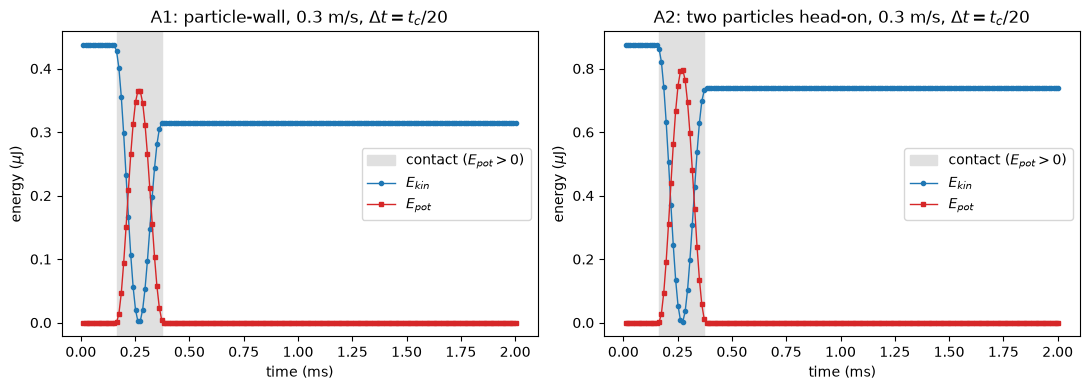


Measured e (rows: impact speed, steps per contact = t_c/dt):
                           A1 e (tab. 0.85)  A2 e (tab. 0.92)
v (m/s) steps per contact                                    
0.1     5                            0.8861            0.9266
        10                           0.8428            0.9166
        20                           0.8481            0.9194
        40                           0.8560            0.9196
0.3     5                            0.8483            0.9241
        10                           0.8445            0.9178
        20                           0.8488            0.9199
        40                           0.8492            0.9198
1.0     5                            0.8922            0.9333
        10                           0.8424            0.9162
        20                           0.8479            0.9193
        40                           0.8493            0.9199

Largest relative error of e over the three speeds:
                  

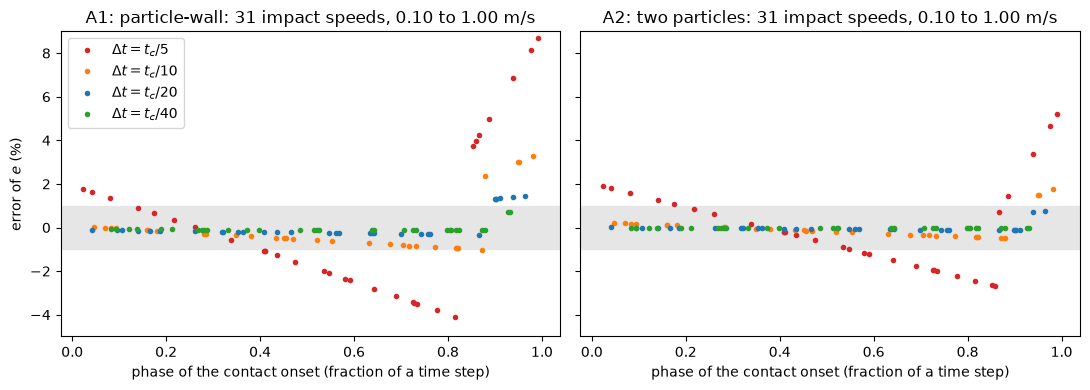


Scan over 31 impact speeds: error of e (%), per time step
                       min   max  mean  share |error|>1 %
num_test dt_fraction                                     
1        0.025       -0.13  0.70 -0.05               0.00
         0.050       -0.32  1.47  0.09               0.19
         0.100       -1.02  3.28 -0.07               0.16
         0.200       -4.09  8.70  0.24               0.84
2        0.025       -0.04 -0.02 -0.03               0.00
         0.050       -0.13  0.77 -0.02               0.00
         0.100       -0.50  1.78  0.01               0.10
         0.200       -2.68  5.22 -0.01               0.65

A1, t_c/20: contact has 20 overlap steps below phase 0.87 and 19 above 0.90; error -0.32 to -0.11 % (20 steps), +1.32 to +1.47 % (19 steps)

The 24 runs of the table, with their phase (A1):
 v_impact  steps_per_contact  phase  steps_with_overlap  rel_error
      0.1                  5 0.8664                   4       4.24
      0.1                 10 0.7328 

In [1]:
# A: E_kin and E_pot through one collision; e against impact speed and time step (load from data/)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Figure 1: one collision at 0.3 m/s, dt = t_c/20; contact = steps with E_pot > 0 ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, name, title in zip(axes, ["A1", "A2"], ["A1: particle-wall", "A2: two particles head-on"]):
    d = np.loadtxt(f"data/A_{name}_v0.3.dat")
    t, epot, ekin = d[:, 1] * 1e3, d[:, 3] * 1e6, d[:, 4] * 1e6      # ms, microjoule
    touching = np.flatnonzero(epot > 0)
    t0, t1 = t[touching[0]], t[touching[-1]]
    ax.axvspan(t0, t1, color="0.88", label="contact ($E_{pot}>0$)")
    ax.plot(t, ekin, "o-", ms=3, lw=1, color="C0", label="$E_{kin}$")
    ax.plot(t, epot, "s-", ms=3, lw=1, color="C3", label="$E_{pot}$")
    ax.set_xlabel("time (ms)")
    ax.set_ylabel("energy ($\\mu$J)")
    ax.set_title(f"{title}, 0.3 m/s, $\\Delta t=t_c/20$")
    ax.legend(loc="center right")
    ek_b, ek_a = ekin[touching[0] - 1], ekin[touching[-1] + 1]
    print(f"{name}: contact from {t0:.4f} to {t1:.4f} ms (duration {t1 - t0 + t[1] - t[0]:.3f} ms, t_c = 0.219 ms); "
          f"E_kin before {ek_b:.4f} uJ, after {ek_a:.4f} uJ, peak E_pot {epot.max():.4f} uJ, "
          f"e = {np.sqrt(ek_a / ek_b):.4f}")
plt.tight_layout()
plt.show()

# --- Table: measured e at 3 speeds x 4 time steps, next to the tabulated value ---
r = pd.read_csv("data/A_restitution.csv")
tab = r.pivot_table(index=["v_impact", "steps_per_contact"], columns="num_test", values="e")
tab.columns = ["A1 e (tab. 0.85)", "A2 e (tab. 0.92)"]
tab.index.names = ["v (m/s)", "steps per contact"]
print("\nMeasured e (rows: impact speed, steps per contact = t_c/dt):")
print(tab.round(4).to_string())
err = r.pivot_table(index="steps_per_contact", columns="num_test", values="rel_error",
                    aggfunc=lambda x: np.abs(x).max()) * 100
err.columns = ["A1 max |error| (%)", "A2 max |error| (%)"]
print("\nLargest relative error of e over the three speeds:")
print(err.round(2).to_string())
for k, name in [(1, "A1"), (2, "A2")]:
    ok = err[f"{name} max |error| (%)"] < 1
    print(f"{name}: within 1 % at all three speeds from {ok[ok].index.min()} steps per contact; "
          f"at 20 steps (t_c/20) the largest error is {err.loc[20, f'{name} max |error| (%)']:.2f} %")
print("Spread of e over the three speeds (max - min):")
print(r.groupby(["num_test", "steps_per_contact"]).e.agg(lambda x: x.max() - x.min()).round(4).unstack(0).to_string())

# --- The cause of the irregular dt dependence: the phase of the contact onset ---
s = pd.read_csv("data/A_phase_scan.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, k, title in zip(axes, [1, 2], ["A1: particle-wall", "A2: two particles"]):
    for frac, c in zip([0.2, 0.1, 0.05, 0.025], ["C3", "C1", "C0", "C2"]):
        g = s[(s.num_test == k) & (s.dt_fraction == frac)]
        ax.plot(g.phase, 100 * g.rel_error, ".", color=c, label=f"$\\Delta t=t_c/{round(1 / frac)}$")
    ax.axhspan(-1, 1, color="0.9", zorder=0)
    ax.set_xlabel("phase of the contact onset (fraction of a time step)")
    ax.set_title(f"{title}: 31 impact speeds, 0.10 to 1.00 m/s")
    ax.set_ylim(-5, 9)
axes[0].set_ylabel("error of $e$ (%)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()
print("\nScan over 31 impact speeds: error of e (%), per time step")
st = s.groupby(["num_test", "dt_fraction"]).rel_error.agg(["min", "max", "mean"]) * 100
st["share |error|>1 %"] = s.groupby(["num_test", "dt_fraction"]).rel_error.apply(lambda x: (x.abs() > 0.01).mean())
print(st.round(2).to_string())
g = s[(s.num_test == 1) & (s.dt_fraction == 0.05)].sort_values("phase")
jump = g[g.steps_with_overlap == g.steps_with_overlap.min()].phase.min()
print(f"\nA1, t_c/20: contact has 20 overlap steps below phase {g[g.steps_with_overlap == 20].phase.max():.2f} "
      f"and 19 above {jump:.2f}; error {100 * g[g.steps_with_overlap == 20].rel_error.min():+.2f} to "
      f"{100 * g[g.steps_with_overlap == 20].rel_error.max():+.2f} % (20 steps), "
      f"{100 * g[g.steps_with_overlap == 19].rel_error.min():+.2f} to "
      f"{100 * g[g.steps_with_overlap == 19].rel_error.max():+.2f} % (19 steps)")
print("\nThe 24 runs of the table, with their phase (A1):")
print(r[r.num_test == 1][["v_impact", "steps_per_contact", "phase", "steps_with_overlap", "rel_error"]]
      .assign(rel_error=lambda x: (100 * x.rel_error).round(2)).to_string(index=False))
short = r.steps_with_overlap < r.steps_per_contact
print(f"\nAll 24 runs: {short.sum()} runs with one overlap step fewer than t_c/dt have errors "
      f"{100 * r[short].rel_error.min():+.2f} to {100 * r[short].rel_error.max():+.2f} %; "
      f"the other {(~short).sum()} runs {100 * r[~short].rel_error.min():+.2f} to {100 * r[~short].rel_error.max():+.2f} %")

## Part B: Validation, granular slope stability

*In the oral you should be able to:* explain why rotating gravity is
equivalent to tilting the floor; explain the angle you found from the
way the particles move; explain what static friction requires of the
contact model, and what would happen to this test without the stored
tangential displacement.

The bed of the starting code (2000 particles, about five layers on the
flat bottom wall, periodic sides) settles under vertical gravity until
$t_\mathrm{tilt} = 0.3$ s. Then gravity rotates about the $y$ axis at a
constant rate, which tilts the bed without moving any wall. Write
`update_parameters` (`RUN=2`).

**Before you run, predict:** if the bed slides over the floor as one
block, at which angle does it start to move? (Only one friction
coefficient matters for that.)

Deliver:

- a **figure** of $E_\mathrm{kin}$ (log scale) against slope angle, for
  the two tilt rates of the run table on one plot, with the onset angle
  $\theta_c$ marked. The kinetic energy creeps up before the bed really
  goes: define your onset (for example the angle where $E_\mathrm{kin}$
  passes $10^{-6}$ J, a mean speed of about 1 cm/s) and state the
  definition;
- a **number**: $\theta_c$, and whether it depends on the tilt rate;
- a **comparison** with your prediction.

Do not be alarmed if the bed fails far below your prediction: that is
the point of this task, not an error in your code. Find out why. Take a
frame of the trajectory at a slope of about 20° and compare the mean
speed of the bottom layer (centres less than 2 mm above the floor) with
the mean speed of the particles above it. What ratio would you expect if
the bottom layer rolled, without slipping, under a bed that slides over
it? What does your measured ratio say about how the bed fails, and why is
the friction coefficient then not what sets $\theta_c$?

*Results (B):* code: [`update_parameters`](code/setparameters.c) (RUN_SLOPE branch), [`extract_frame.py`](code/extract_frame.py); data: [B_rate20.dat](data/B_rate20.dat), [B_rate10.dat](data/B_rate10.dat), [B_frame_20deg.dat](data/B_frame_20deg.dat). Figure and printed numbers are in the code cell below.

**B0 Prediction (written before any run).**
- **Model.** If the whole bed slides as one block over the floor, the force balance along the slope gives $m g\sin\theta = \mu\, m g\cos\theta$, so it starts to move at $\tan\theta_c = \mu$.
- **Which $\mu$.** The surface that slips is bottom layer against floor, so $\mu$ is the **particle-wall** friction coefficient of the model table, $\mu_w = 0.45$: $\theta_c = \arctan 0.45 = 24.2^\circ$. The particle-particle value 0.50 ($26.6^\circ$) would only matter if two layers of the bed slid over each other; in a rigid block the particle-particle contacts do not slip.
- **Note.** The ramp of the run ends at $24^\circ$, just below $24.2^\circ$: if the bed behaved like this block, it would not have started to move in our run.

**B1 Onset angle**
- **Definition.** $\theta_c = \dot\theta\,(t_c - t_\mathrm{tilt})$, where $t_c$ is the first table line after $t_\mathrm{tilt} = 0.3$ s with $E_\mathrm{kin} > 10^{-6}$ J (about 1 cm/s mean speed). The settled bed sits at $10^{-8}$ to $3\times10^{-8}$ J ($2.9\times10^{-8}$ J at $t_\mathrm{tilt}$), well below the threshold.
- **Result.** $\theta_c = 11.7^\circ$ at 20 °/s and $12.1^\circ$ at 10 °/s. Thresholds of $5\times10^{-7}$ to $2\times10^{-6}$ J move each by $-0.5^\circ/+0.6^\circ$. So **$\theta_c \approx 12^\circ \pm 0.6^\circ$**.
- **Rate dependence.** The 10 °/s run starts $0.4^\circ$ later (+0.37, +0.37, +0.31° at the three thresholds): the same sign each time, but the size of the threshold effect, and we have one run per rate. So at most a 3 % effect; we do not claim more. Between $10^\circ$ and $15^\circ$ the two curves lie nearly on top of each other.
- **Where the rise starts.** $E_\mathrm{kin}$ leaves its noise floor at 9 to $10^\circ$ ($10^{-7}$ J is passed at $10.4^\circ$ and $10.1^\circ$); the definition fixes the number, not the shape.

**B2 Comparison with the prediction.** $\theta_c \approx 12^\circ$ is **half** of the predicted $24.2^\circ$ ($\tan 12^\circ = 0.21$, against $\mu_w = 0.45$). A block sliding on the floor would not have moved at all within our $24^\circ$ ramp, so the bed does not fail that way.

**B3 Bottom layer at $19.8^\circ$** (frame at $t = 1.292$ s of the 20 °/s run; $z = 0$ is the floor, the lowest centre is at 0.97 mm, one radius).
- **Measured.** Bottom layer (centres $< 2$ mm): 361 particles, mean speed 0.137 m/s. Above: 1639 particles, 0.240 m/s. Both have a spread (std) of 0.017 m/s. **Ratio 0.57** (0.57, 0.57, 0.58 for cuts at 1.5, 2.0, 2.5 mm).
- **Above the layer** the speed is nearly uniform: 0.233 to 0.250 m/s in 1 mm slices, +7 % over 8 mm. The upper bed moves as one block.
- **Expected if the bottom layer rolls without slipping.** The contact point with the floor is at rest, so the top of a sphere moves at twice its centre speed. A bed carried on the tops moves at $2v_c$: ratio **0.5**. If the whole bed slid over the floor the bottom layer would move with the rest: ratio 1.
- **What the ratio says.** 0.57 is close to 0.5 and far from 1: the bottom layer rolls on the floor and the bed above rides on it. A little more than 0.5 is plausible, since the bed above touches the spheres off their tops (we did not test this). The trajectory file has no spins, so rolling is inferred from the speeds.
- **Why $\mu$ does not set $\theta_c$.** $\tan\theta = \mu_w$ needs the floor contacts to slide, i.e. to reach the Coulomb cap $\mu_w F_n$. A rolling contact point is at rest: static friction only holds it, below the cap. The contact model has no rolling resistance, and a single sphere with static friction rolls down a slope at any angle. So the finite $\theta_c$ must come from the spheres around it, i.e. from the packing and not from $\mu_w$. We did not vary $\mu_w$: this is what fits the data, not a tested result.

**Oral prep**
- **Q:** Why is rotating gravity equivalent to tilting the floor?
  **A:** Contact forces depend only on relative positions and velocities, so only the direction of $\mathbf g$ relative to the floor matters: along the floor $g\sin\theta$, normal to it $g\cos\theta$, in both pictures. We set $\mathbf g = g(\sin\theta, 0, -\cos\theta)$ in [`update_parameters`](code/setparameters.c). The sides are periodic, so there are no side walls to move, and the floor stays the plane $z = 0$. Rotating $\mathbf g$ in a fixed frame also adds no fictitious forces.
- **Q:** Explain the angle you found from the way the particles move.
  **A:** We find $\theta_c \approx 12^\circ$, half of $\arctan\mu_w = 24.2^\circ$. At $19.8^\circ$ the bottom layer moves at 0.57 of the speed of the bed above it (0.137 against 0.240 m/s): near the rolling value 0.5, far from 1. The bottom layer rolls and the bed rides on it, so the floor contacts do not slide and $\mu_w$ does not set the onset.
- **Q:** What does static friction require of the contact model, and what would happen to this test without it?
  **A:** A tangential spring acting on a displacement stored per contact, kept for as long as the contact lasts (neighbour list in [`nbrlist.c`](code/nbrlist.c), used in [`calculate_forces_pp` and `_pw`](code/forces.c)), so the force is nonzero at rest, plus the Coulomb cap $|F_t| \le \mu |F_n|$ that switches from sticking to sliding. Without the stored displacement friction would only act on the sliding speed: zero for a bed at rest, so the bed could not be held and would creep at any angle.

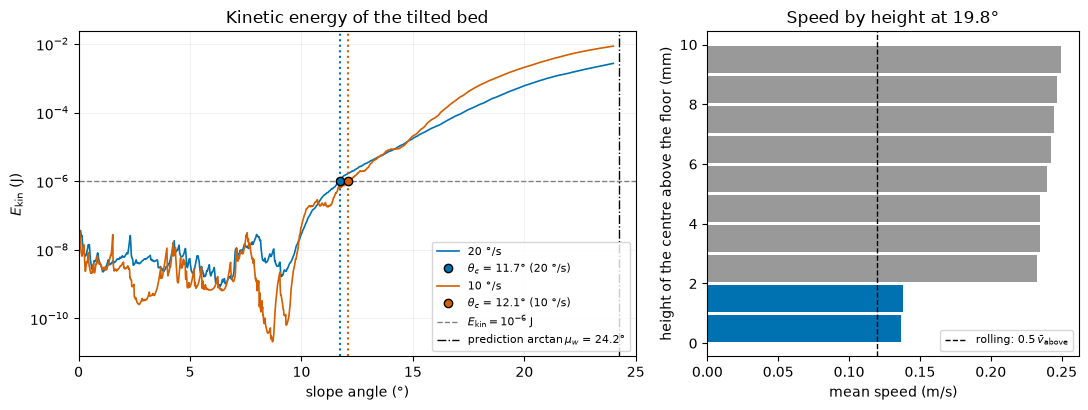

onset: first time after t_tilt = 0.3 s with E_kin > 1e-06 J, angle = rate*(t - t_tilt)
  20 deg/s: theta_c = 11.71 deg   (threshold 5e-7 / 1e-6 / 2e-6 J: 11.23 / 11.71 / 12.32 deg);  1e-7 J would give 10.38 deg;  E_kin of the settled bed at t_tilt = 2.9e-08 J
  10 deg/s: theta_c = 12.08 deg   (threshold 5e-7 / 1e-6 / 2e-6 J: 11.60 / 12.08 / 12.63 deg);  1e-7 J would give 10.12 deg;  E_kin of the settled bed at t_tilt = 2.9e-08 J
  rate 10 minus rate 20: +0.37 deg at 1e-6 J; +0.37 at 5e-7; +0.31 at 2e-6
prediction: arctan(0.45) = 24.23 deg; ramp ends at 24 deg
frame: t = 1.2917 s, slope 19.83 deg, 2000 particles, lowest centre 0.974 mm
bottom layer (z < 2 mm): n = 361, mean speed 0.1374 m/s (std 0.017)
above:                   n = 1639, mean speed 0.2397 m/s (std 0.017)
ratio bottom/above = 0.574   (rolling without slipping: 0.5; whole bed sliding on the floor: 1)
  cut 1.5 mm: n = 361, ratio = 0.574
  cut 2.0 mm: n = 361, ratio = 0.574
  cut 2.5 mm: n = 372, ratio = 0.584
mean speed in

In [2]:
# B: E_kin against slope angle for both tilt rates; speed of the bottom layer against the layers above
import re
import numpy as np
import matplotlib.pyplot as plt

T_TILT, E_ONSET = 0.3, 1e-6                 # s; onset threshold on E_kin in J
MU_W = 0.45                                 # particle-wall friction coefficient of the model table
runs = {20: "data/B_rate20.dat", 10: "data/B_rate10.dat"}   # tilt rate in deg/s -> table of the run
colour = {20: "#0072B2", 10: "#D55E00"}

def onset_angle(rate, t, ekin, thr=E_ONSET):
    """Angle rate*(t - t_tilt) at the first table line after t_tilt with E_kin > thr."""
    i = np.argmax((t > T_TILT) & (ekin > thr))
    return rate * (t[i] - T_TILT)

tab, theta_c = {}, {}
for rate, path in runs.items():
    d = np.loadtxt(path)                    # columns: step time Z Epot Ekin Etot N_silo
    tab[rate] = (d[:, 1], d[:, 4])
    theta_c[rate] = onset_angle(rate, *tab[rate])
sens = {r: [onset_angle(r, *tab[r], thr) for thr in (5e-7, 1e-6, 2e-6)] for r in runs}
theta_pred = np.degrees(np.arctan(MU_W))

# frame at about 20 degrees: x y z radius speed (z = 0 is the floor)
with open("data/B_frame_20deg.dat") as f:
    t_frame = float(re.search(r"at t = (\S+) s", f.readline()).group(1))
z, speed = np.loadtxt("data/B_frame_20deg.dat", usecols=(2, 4)).T
angle_frame = 20 * (t_frame - T_TILT)
bottom = z < 2e-3                           # centres less than 2 mm above the floor
v_bot, v_up = speed[bottom].mean(), speed[~bottom].mean()
ratio = v_bot / v_up

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
for rate in runs:
    t, ek = tab[rate]
    m = t >= T_TILT
    ax.semilogy(rate * (t[m] - T_TILT), ek[m], color=colour[rate], lw=1.2, label=f"{rate} °/s")
    ax.axvline(theta_c[rate], color=colour[rate], ls=":", lw=1.5)
    ax.plot(theta_c[rate], E_ONSET, "o", color=colour[rate], mec="k", zorder=5,
            label=rf"$\theta_c$ = {theta_c[rate]:.1f}° ({rate} °/s)")
ax.axhline(E_ONSET, color="grey", ls="--", lw=1, label=r"$E_\mathrm{kin}=10^{-6}$ J")
ax.axvline(theta_pred, color="k", ls="-.", lw=1, label=rf"prediction $\arctan\mu_w$ = {theta_pred:.1f}°")
ax.set_xlim(0, 25)
ax.set_xlabel("slope angle (°)")
ax.set_ylabel(r"$E_\mathrm{kin}$ (J)")
ax.set_title("Kinetic energy of the tilted bed")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3, which="both", lw=0.4)

edges = np.arange(0, 10.5e-3, 1e-3)         # speed profile in 1 mm height slices
mid = 0.5 * (edges[:-1] + edges[1:]) * 1e3
prof = np.array([speed[(z >= a) & (z < b)].mean() if ((z >= a) & (z < b)).any() else np.nan
                 for a, b in zip(edges[:-1], edges[1:])])
bx.barh(mid, prof, height=0.9, color=np.where(mid < 2, colour[20], "#999999"))
bx.axvline(0.5 * v_up, color="k", ls="--", lw=1, label=r"rolling: $0.5\,\bar v_\mathrm{above}$")
bx.set_xlabel("mean speed (m/s)")
bx.set_ylabel("height of the centre above the floor (mm)")
bx.set_title(f"Speed by height at {angle_frame:.1f}°")
bx.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

print(f"onset: first time after t_tilt = {T_TILT} s with E_kin > {E_ONSET:g} J, angle = rate*(t - t_tilt)")
for rate in runs:
    t, ek = tab[rate]
    print(f"  {rate:2d} deg/s: theta_c = {theta_c[rate]:.2f} deg   (threshold 5e-7 / 1e-6 / 2e-6 J: "
          f"{sens[rate][0]:.2f} / {sens[rate][1]:.2f} / {sens[rate][2]:.2f} deg);  "
          f"1e-7 J would give {onset_angle(rate, t, ek, 1e-7):.2f} deg;  E_kin of the settled bed at t_tilt = {ek[t <= T_TILT][-1]:.1e} J")
print(f"  rate 10 minus rate 20: {theta_c[10] - theta_c[20]:+.2f} deg at 1e-6 J; "
      f"{sens[10][0] - sens[20][0]:+.2f} at 5e-7; {sens[10][2] - sens[20][2]:+.2f} at 2e-6")
print(f"prediction: arctan({MU_W}) = {theta_pred:.2f} deg; ramp ends at 24 deg")
print(f"frame: t = {t_frame:.4f} s, slope {angle_frame:.2f} deg, {len(z)} particles, lowest centre {z.min()*1e3:.3f} mm")
print(f"bottom layer (z < 2 mm): n = {bottom.sum()}, mean speed {v_bot:.4f} m/s (std {speed[bottom].std():.3f})")
print(f"above:                   n = {(~bottom).sum()}, mean speed {v_up:.4f} m/s (std {speed[~bottom].std():.3f})")
print(f"ratio bottom/above = {ratio:.3f}   (rolling without slipping: 0.5; whole bed sliding on the floor: 1)")
for cut in (1.5e-3, 2.0e-3, 2.5e-3):
    b = z < cut
    print(f"  cut {cut*1e3:.1f} mm: n = {b.sum()}, ratio = {speed[b].mean()/speed[~b].mean():.3f}")
print(f"mean speed in 1 mm slices above 2 mm: {np.nanmin(prof[2:10]):.3f} to {np.nanmax(prof[2:10]):.3f} m/s")

## Part C: Building the silo

*In the oral you should be able to:* state the wall-function contract and
walk through your cylinder implementation and your edge of the hole,
including why your point is the closest one; explain why the fill needs no separate randomisation; interpret
your packing profile and the bulk density you use for Beverloo.

All of Part C runs inside the one silo run of the run table (`RUN=3`,
$D = 7\,d_p$): the fill settles on the closed plate until
$t_\mathrm{open} = 0.3$ s, after which the orifice opens. Parts C3 and C4
use the part before $t_\mathrm{open}$, Part D the part after.

### C1) Cylindrical wall

Write `cylinder_wall`. The contract (overlap test, $\mathbf{r}_{iw}$
from the closest wall point to the particle centre, $\mathbf{v}_w$) is
documented at the top of `walls.c`; compare with `bottom_wall`.

### C2) Bottom plate with a circular orifice

The flat plate is given in `silo_bottom_wall`; it shows the wall contract
at work. What is missing is the **edge of the hole**: a particle whose
centre is over the open hole, but within one radius of the plane of the
plate, can still touch the plate where the hole begins. Work out which
point of the plate is then closest to the particle centre, and complete
`silo_bottom_wall` with that contact. Open the orifice at
$t_\mathrm{open}$ in `update_parameters`.

Deliver, in the results cell: the **closest wall point** and
$\mathbf{r}_{iw}$ for a centre over the hole, as a formula, with a
sketch or one sentence that shows why it is the closest point; and how
you convinced yourself that your implementation is right. Without the
edge the code still runs and the silo still empties: say what a particle
at the edge of the hole would do then.

### C3) Filling and settling

Write `initialise_positions_silo`: a loose lattice clipped to the
cylinder, as the `\todo` describes. Gravity and the closed plate do the
rest.

Deliver a **figure** of $E_\mathrm{kin}$ and the coordination number
$Z$ against time for $t < t_\mathrm{open}$, showing that the fill has
come to rest before the orifice opens, and a **snapshot** of the settled
bed (OVITO, sliced).

### C4) The packing

From the last trajectory frame before $t_\mathrm{open}$, deliver:

- a **number**: the bulk solids volume fraction $\phi$ and the bulk
  density $\rho_b = \phi \rho_p$, which you need for Beverloo. Use a core
  region away from the walls: centres closer than $R_\mathrm{cyl} - 2d_p$
  to the axis, and between $2d_p$ above the plate and $3d_p$ below the
  highest particle. $\phi$ is the summed volume of the particles whose
  centre is in the core, divided by the core volume;
- a **number**: the coordination number $Z$ of the settled packing (the
  table has it);
- a **figure** of the radial profile of the particle centres: the number
  of centres per volume in thin cylindrical shells (0.2 mm) over the core
  height, times the mean particle volume. Near the wall this is *not* a
  local volume fraction, and it can exceed 0.74: the centres of a layer
  of spheres against a wall all sit at one distance from it.

Then discuss: why does the profile oscillate near the wall, and over how
many particle diameters? What does that imply for how wide a silo has to
be, compared with its orifice?

*Results (C):* …

In [3]:
# C3/C4: settling (E_kin and Z against time); bulk phi and rho_b in the core; radial profile

## Part D: Discharge and the Beverloo law

*In the oral you should be able to:* explain why the discharge rate does
not depend on the fill height (and why a liquid's does); derive which
quantities the Beverloo scaling can be built from dimensionally; explain
what happens at small orifices and why.

Write `count_in_silo`: then the last column of the table is $N(t)$, the
number of particles still in the silo. Time zero of the discharge is
$t_\mathrm{open} = 0.3$ s.

### D1) Discharge

From the silo run at $D = 7\,d_p$, deliver **snapshots** at three times
(early, middle, late), sliced through the axis and coloured by speed,
and mark on them where the material flows and where it is stagnant.
Describe the shape of the flowing region and say what it means for how a
silo empties: which grains leave first, those at the top or those at the
bottom?

### D2) Discharge rate

From the same run, extract the steady discharge rate $Q$, in particles
per second and in g/s (mean particle mass above).

Deliver:

- a **figure** of $N(t)$ with the fitted window marked. Fit from the
  moment 10 % of the particles has left until 60 % has left (or the run
  ends): the start-up and the last, shallow part of the fill are not
  steady;
- a **figure** of the rate against the number of particles left (a
  running slope over about 0.1 s), which is where the constancy is
  actually visible;
- a **number**: $Q$ with an error estimate, and evidence that it is
  constant while the fill height drops. Fit the first and the second half
  of the window separately and compare: that is the signature which
  distinguishes a silo from a water clock.

Then explain the physics: why does the head of material above the orifice
not matter, and why does it matter for a draining water tank?

### D3) Beverloo scaling

Add orifices of 6, 8 and 9 $d_p$ (run table) to your 7 $d_p$.

Deliver:

- a **table** of $D$, $D/d_p$, $Q$ and its error, per run;
- a **figure** of $Q^{2/5}$ against $D$ with a linear fit, since Beverloo
  predicts a straight line whose intercept gives $k\,d_p$;
- **numbers**: your fitted $k$ and $C$ with uncertainties, using your
  $\rho_b$ from C4, next to the literature values, and a quantitative
  statement about the quality of the fit;
- a sentence on which of your fitted constants you trust more, and why.

Then derive, dimensionally, why the exponent is $5/2$ for a
three-dimensional silo, and state what it would be in two dimensions.

Finally, the cost of doing better. At $D = 9\,d_p$ the silo is only two
orifices wide, while Beverloo assumes a silo much wider than its
orifice. Estimate, from your own run times, what the four D3 runs would
cost in a silo twice as wide with the same fill height. Say which
factors of that estimate scale with the number of particles and which
do not, and why the time step does not change.

### D4) The small-orifice limit

Run $D = 3\,d_p$.

Deliver a **figure** of $N(t)$ for this run next to your $7\,d_p$ run on
the same axes, a **snapshot** of the blocked orifice, and a description
of what you observe. Explain the mechanism qualitatively, and say what
this implies for the range of validity of the Beverloo correlation you
fitted in D3.

*Results (D):* Q(t) …, Beverloo fit k = …, C = …, small-orifice
observations …

In [4]:
# D: snapshots; N(t) and Q with the half-window check; Q^(2/5) against D with linear fit; the small orifice

## Lessons learned

What would you do differently if you started over? What surprised you?
What in your results still bothers you? This is the last assignment of
the course: also say which of the four methods you would reach for first
if a new problem landed on your desk, and why.

*Lessons learned:* …

## Hand-in

One zip per group, layout exactly:

```
<group>_A4.zip
├── A4.ipynb     this notebook, filled in and executed
│                (all outputs present; task cells untouched)
├── A4.html      python3 nb2html.py A4.ipynb
├── code/        all .c/.h + README.md; must build with
│                gcc -O3 *.c -o dem -lm    (no binaries)
└── data/        every data file and image this notebook loads
                 (no trajectories)
```

Long runs are done in the terminal; record the exact commands in the
*Build & run log* and let the notebook load the saved output from
`data/`. Handed in executed, the notebook must open and display without
rerunning anything.

**Before you submit,** check your own zip:

```
python3 check_my_submission.py <group>_A4.zip --release A4.ipynb
```

where `--release` is a freshly downloaded, unmodified `A4.ipynb`. It
verifies the layout, that the task cells are untouched, that every cell
has been executed, that your C code compiles, and that every path and
link in the notebook is relative and present in the zip. Fix what it
reports, then submit. Setting up the Python environment
(`requirements.txt`, both helper scripts) is described on the Canvas page
*Working on the assignments*.

All four notebooks must be handed in before the oral examinations start.